In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
conn = sqlite3.connect("../data/exoplanets.db")
df = pd.read_sql("SELECT * from planets", conn)

rv = df[(df["discoverymethod"] == "Radial Velocity") 
        & df["pl_rade"].notna() 
        & df["pl_bmasse"].notna()]
print(len(rv), "radial velocity planets with both radius and mass")

1168 radial velocity planets with both radius and mass


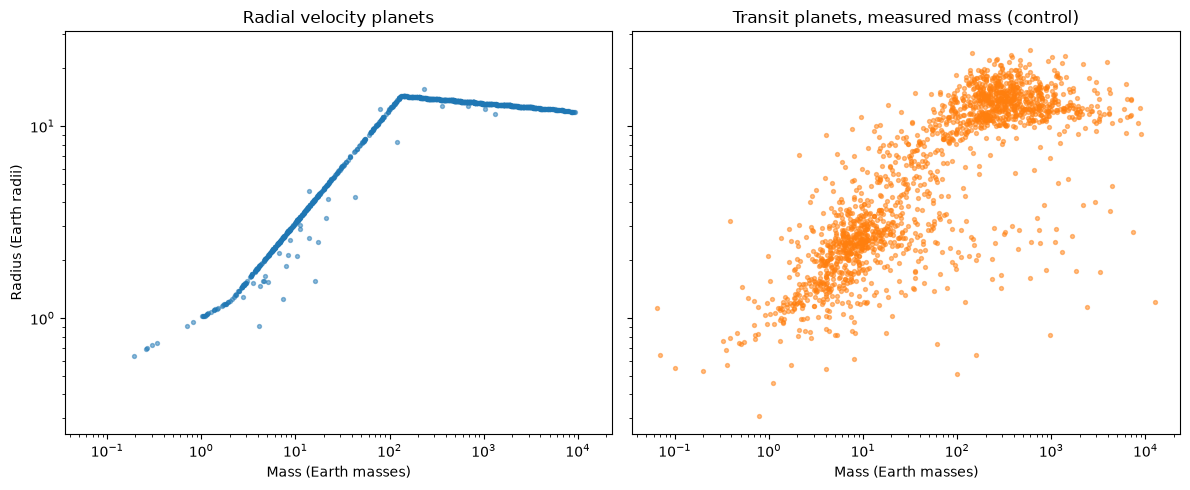

In [9]:
import os
os.makedirs("../figures", exist_ok=True)

control = df[(df["discoverymethod"] == "Transit")
             & (df["pl_bmassprov"] == "Mass")
             & df["pl_rade"].notna() & df["pl_bmasse"].notna()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

ax1.scatter(rv["pl_bmasse"], rv["pl_rade"], s=8, alpha=0.5)
ax1.set_title("Radial velocity planets")

ax2.scatter(control["pl_bmasse"], control["pl_rade"], s=8, alpha=0.5, color="C1")
ax2.set_title("Transit planets, measured mass (control)")

for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Mass (Earth masses)")
ax1.set_ylabel("Radius (Earth radii)")
plt.tight_layout()
plt.savefig("../figures/radius_chack.png", dpi=150, bbox_inches="tight")
plt.show()